# TUTORIAL <span style="color:orange;">***MASAÏ***</span><img width='64' style="float:right;margin:0 10px 0 20px;" src="images/masai.png" />

Back to the main [Index](Index.ipynb)

## Part 3. Handling series of 1D spectra

#### Various imports and graphics settings

In [1]:
from __future__ import print_function

#### Loading the <span style="color:orange;">***MASAÏ***</span> library

In [2]:
from masai.api import *

MASAI api loaded: version 0.2.2.18

The current directory is </Users/christian/Dropbox/PycharmProjects/masai/doc/tutorial>
MASAI root directory is </Users/christian/Dropbox/PycharmProjects/masai>


#### Set up the general location of data

In [3]:
masai = os.environ.get('MASAI','.')
# You should set the MASAI environnement variable before running these exemples')
# or change the two following paths according to your installation
DATADIR = os.path.join(masai,'doc/tutorial/exemples')
FIGDIR = os.path.join(masai,'doc/tutorial/figures')

## Load a series of 1D fids

In [4]:
def read():
    """ This function will be call each time we want to reset the data to original """
    expnos = [50,85,105,144,164,184,194]
    expnos.reverse()
    return Bruker(
            data_dir=DATADIR, 
            user = 'user', 
            name = 'SERIES', 
            expnos = expnos,
            varpars = "TE"
          ) 
sources = read()
# print file informations
sources

***Bruker Source***
- path: /Users/christian/Dropbox/PycharmProjects/masai/doc/tutorial/exemples/user/nmr/SERIES
- datatype: 1D NMR FIDSER
- pulse program: zg
- n: 7, TD: 6144
- F1 limits: 224.99 to 335.012 {}
- F2 limits: 0.00 to 92.145 ms

We can check that the various experiments are properly read and stacked in a single 2D array (only the 5 fisrt rows are displayed using the `head()` function)

In [5]:
sources.real.head()

,0.0,0.015,0.03,0.045,0.06,0.075,0.09,0.105,0.12,0.135,...,92.01,92.025,92.04,92.055,92.07,92.085,92.1,92.115,92.13,92.145
224.9870,-12.078691,-20.879722,-9.000152,-7.444616,-4.883248,-4.716552,0.559170,5.986791,11.764232,13.279835,...,0,0,0,0,0,0,0,0,0,0
244.9878,-9.384140,-16.995561,-7.145717,-4.030292,-1.016278,-0.111965,3.617253,9.401441,14.092749,15.036778,...,0,0,0,0,0,0,0,0,0,0
259.9952,-8.095404,-12.300335,-0.868080,2.602716,5.201841,5.208370,9.118863,13.885576,17.380419,15.171592,...,0,0,0,0,0,0,0,0,0,0
274.9956,-7.120038,-10.043088,0.646327,4.951362,6.573925,6.458152,10.023829,14.635924,17.295548,14.122889,...,0,0,0,0,0,0,0,0,0,0
289.5940,-26.103325,-32.013079,11.175683,25.287583,29.596644,26.068615,36.024330,48.427598,55.067244,38.007160,...,0,0,0,0,0,0,0,0,0,0


## Plots

taking horizontal (axis=1) section by index at index 2


<IPython.core.display.Javascript object>


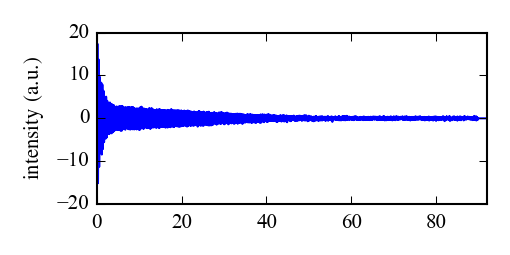

In [6]:
p = Plot1d(sources.get_row(2, byindex=True ))  

## How to process a series of fid?

Exactly the same as a unique spectrum

Exponential apodization lb:50.00
Zero-filling to si:8192
Fourier transform with si:8192
clipping along axis -1
Phasing phc0:140.00, phc1:0.00
Phasing phc0:180.00, phc1:0.00


<IPython.core.display.Javascript object>


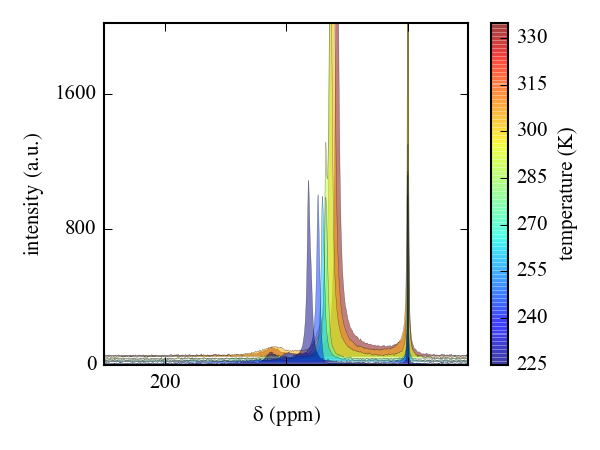

***Bruker Source***
- path: /Users/christian/Dropbox/PycharmProjects/masai/doc/tutorial/exemples/user/nmr/SERIES
- datatype: 1D NMR FIDSER
- pulse program: zg
- n: 7, SI: 4082
- F1 limits: 224.99 to 335.012 {}
- F2 limits: 249.98 to -49.978 ppm



In [7]:
sources = read() # reading this each avoid problem with multiple calls

Process(sources, transform="em 50; zf 0; ft; cl -50 250; pk 140 0 --pivot -0.04") 
Process(sources, 
    transform="""pk 180 0 --pivot -0.04  --ediff 2 --bound_phc0 360 
                --bound_phc1 180 --fit_phc1 --gamma 1 --exp --byrow""")# 

p = Stackplot(sources, offset=.1, figsize=(4,3), ylim=(-1, 2020), ylabel='temperature (K)')
print(sources)

In [9]:
# We wll try here to normalize the xenon spectra relative to the gas pic (-3, 3 ppm)

# make an array of integrals for the gaz pic
id0 = sources.get_index(-3, axis=-1)
id1 = sources.get_index(3, axis=-1)

intg = sources.data.iloc[:, id1:id0].sum(axis=1)
sources.data = (sources.data.T / intg).T
print('gaz signal intensity', intg)

gaz signal intensity 224.9870    (11895.4980986-262.132649998j)
244.9878    (11200.1730274-2737.76834945j)
259.9952    (13661.0394824-356.972104629j)
274.9956     (16026.9023494-199.25954377j)
289.5940    (62126.0789535+857.824962705j)
304.9910     (103799.364246-5036.9559598j)
335.0125    (73153.4413093-1139.21810155j)
dtype: complex128


<IPython.core.display.Javascript object>


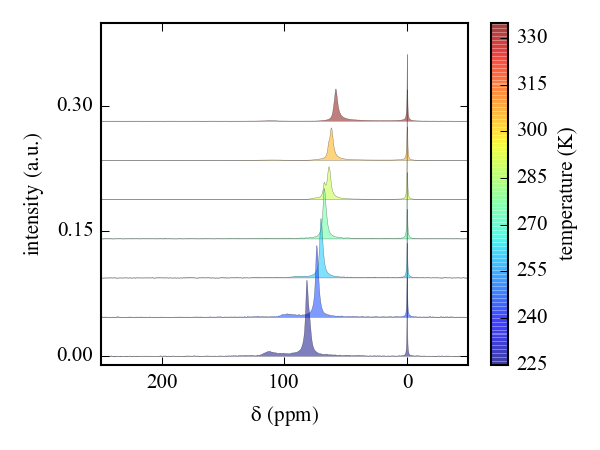

In [15]:
p = Stackplot(sources, offset=50., figsize=(4,3), ylim=(-.01, 0.4) , ylabel='temperature (K)')

Back to the main [Index](Index.ipynb)